# Giai đoạn 1: Thu thập và làm sạch dữ liệu PM2.5 + thời tiết Hà Nội

**Loại công việc: data engineering / chuẩn bị dữ liệu** (chưa phải analysis, mining hay ML).
Mục tiêu là tạo ra **một bảng sạch, mỗi dòng là một giờ** theo giờ địa phương `Asia/Ho_Chi_Minh`, để Giai đoạn 2 (analysis) và 3 (mining) dùng chung.

Các bước:
1. Tải PM2.5 theo giờ của trạm Đại sứ quán Mỹ tại Hà Nội (chương trình AirNow DOS), lấy qua **kho lưu trữ mở của OpenAQ trên AWS S3** (không cần API key), vì trang gốc `dosairnowdata.org` không còn truy cập được.
2. (Tùy chọn) Liệt kê các trạm khác quanh Hà Nội qua OpenAQ API, cần API key.
3. Tải thời tiết theo giờ từ Open-Meteo Historical Weather API (dữ liệu tái phân tích ERA5).
4. Kiểm tra chất lượng: múi giờ, giá trị thiếu, giá trị âm, ngoại lai, giờ trùng.
5. Ghép theo giờ, báo tỷ lệ thiếu theo năm/tháng, lưu bảng sạch.

> Các chỗ đánh dấu **[GIẢ ĐỊNH]** là quyết định em tạm chọn, cần anh xem lại.

In [1]:
# Thư viện và cấu hình chung
from pathlib import Path
import io, os, time, json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

TZ = "Asia/Ho_Chi_Minh"          # Việt Nam dùng UTC+7 cố định, không có giờ mùa hè (DST)
YEARS = list(range(2015, pd.Timestamp.today().year + 1))  # [GIẢ ĐỊNH] khoảng năm; bước kiểm tra bên dưới sẽ cho biết năm nào thực sự có dữ liệu

# Toạ độ Đại sứ quán Mỹ, 7 Láng Hạ, Ba Đình  [GIẢ ĐỊNH] gần đúng, cần đối chiếu với metadata trạm
LAT, LON = 21.0219, 105.8188

BASE = Path(os.environ.get("HANOI_AQ_DIR", "."))   # đặt biến môi trường để đổi thư mục gốc
RAW = BASE / "data" / "raw"
CLEAN = BASE / "data" / "clean"
REPORT = BASE / "reports"
for p in (RAW / "airnow", RAW / "openmeteo", RAW / "openaq", CLEAN, REPORT):
    p.mkdir(parents=True, exist_ok=True)

SESSION = requests.Session()
SESSION.headers["User-Agent"] = "hanoi-aq-study/0.1 (personal research)"

## 1. PM2.5 trạm Đại sứ quán Mỹ (AirNow DOS, qua kho lưu trữ OpenAQ)

**Nguồn gốc:** Bộ Ngoại giao Mỹ đo PM2.5 bằng thiết bị BAM (Beta Attenuation Monitor) tại Đại sứ quán, 7 Láng Hạ, và công bố qua AirNow. Trước đây có file CSV theo năm tại `dosairnowdata.org`, nhưng tháng 3/2025 Bộ Ngoại giao ngừng chia sẻ dữ liệu này và đến nay (11/2026) trang đó không truy cập được.

**Cách lấy:** OpenAQ đã thu thập dữ liệu AirNow theo thời gian thực từ 2016 và lưu bản sao công khai trên AWS S3 (`s3://openaq-data-archive`), không cần API key. Mỗi file là một ngày (theo ngày UTC) của một trạm, đường dẫn dạng
`records/csv.gz/locationid=<id>/year=<YYYY>/month=<MM>/location-<id>-<YYYYMMDD>.csv.gz`.

Trạm Đại sứ quán Mỹ có 2 mã location nối tiếp nhau (toạ độ gần như trùng, 21.0219, 105.8188):
- `2539` "US Diplomatic Post: Hanoi": 30/01/2016 → 09/11/2016
- `7441` "Hanoi" / "US Diplomatic Post: Hanoi": 10/11/2016 → 09/04/2025

Cột: `location_id, sensors_id, location, datetime, lat, lon, parameter, units, value`. `datetime` có offset `+07:00` (giờ địa phương). Không có cột QC như file gốc; giá trị thiếu mã hoá `-999`.

**Lựa chọn khác:** OpenAQ API v3 (cần key, cùng dữ liệu nhưng kèm `period` rõ ràng), các trạm của Sở TN&MT Hà Nội (nhiều trạm nhưng chuỗi ngắn), hoặc bản lưu `dosairnowdata.org` trên Internet Archive (nếu mạng cho phép, để đối chiếu giá trị `Raw Conc.` gốc).

In [2]:
import re, gzip
from concurrent.futures import ThreadPoolExecutor

S3 = "https://openaq-data-archive.s3.amazonaws.com"
OPENAQ_LOCATIONS = [2539, 7441]   # trạm Đại sứ quán Mỹ, 2 mã nối tiếp

def list_s3_keys(loc):
    keys, token = [], None
    while True:
        p = {"list-type": "2", "prefix": f"records/csv.gz/locationid={loc}/", "max-keys": "1000"}
        if token:
            p["continuation-token"] = token
        t = SESSION.get(S3 + "/", params=p, timeout=60).text
        keys += re.findall(r"<Key>([^<]+)</Key>", t)
        m = re.search(r"<NextContinuationToken>([^<]+)<", t)
        if not m:
            return keys
        token = m.group(1)

def fetch_key(key):
    out = RAW / "airnow" / Path(key).name
    if out.exists() and out.stat().st_size > 0:
        return out
    for attempt in range(3):
        r = SESSION.get(f"{S3}/{key}", timeout=60)
        if r.status_code == 200 and r.content[:2] == b"\x1f\x8b":   # đúng là file gzip
            out.write_bytes(r.content)
            return out
        time.sleep(2 * (attempt + 1))
    print("Lỗi tải", key, r.status_code)
    return None

airnow_files = []
for loc in OPENAQ_LOCATIONS:
    keys = list_s3_keys(loc)
    with ThreadPoolExecutor(6) as ex:
        files = [f for f in ex.map(fetch_key, keys) if f is not None]
    print(f"location {loc}: {len(keys)} file ngày trên S3, {len(files)} file có trong cache")
    airnow_files += files

location 2539: 283 file ngày trên S3, 283 file có trong cache


location 7441: 2578 file ngày trên S3, 2578 file có trong cache


In [3]:
raw_pm = pd.concat([pd.read_csv(f) for f in airnow_files], ignore_index=True)
print(raw_pm.shape)
print(raw_pm.groupby(["location_id", "location", "parameter", "units"]).size())
print("Offset múi giờ trong chuỗi datetime:", raw_pm["datetime"].str[-6:].value_counts().to_dict())
raw_pm.head()

(66141, 9)
location_id  location                        parameter  units
2539         US Diplomatic Post: Hanoi-2539  pm25       µg/m³     6754
7441         Hanoi-7441                      pm25       µg/m³    54936
             US Diplomatic Post: Hanoi-7441  pm25       µg/m³     4451
dtype: int64
Offset múi giờ trong chuỗi datetime: {'+07:00': 66141}


,location_id,sensors_id,location,datetime,lat,lon,parameter,units,value
0,2539,5049,US Diplomatic Post: Hanoi-2539,2016-01-30T07:00:00+07:00,21.02177,105.819002,pm25,µg/m³,-999.0
1,2539,5049,US Diplomatic Post: Hanoi-2539,2016-01-30T08:00:00+07:00,21.02177,105.819002,pm25,µg/m³,42.0
2,2539,5049,US Diplomatic Post: Hanoi-2539,2016-01-30T09:00:00+07:00,21.02177,105.819002,pm25,µg/m³,42.2
3,2539,5049,US Diplomatic Post: Hanoi-2539,2016-01-30T10:00:00+07:00,21.02177,105.819002,pm25,µg/m³,48.7
4,2539,5049,US Diplomatic Post: Hanoi-2539,2016-01-30T11:00:00+07:00,21.02177,105.819002,pm25,µg/m³,41.6


### 1.1 Chuẩn hoá thời gian và quy ước đầu giờ / cuối giờ

Ta tạo cột `time` là timestamp **có gắn múi giờ** `Asia/Ho_Chi_Minh` (tz-aware). Lý do: khi ghép với thời tiết hay dữ liệu UTC khác (ví dụ điểm cháy FIRMS dùng UTC), pandas sẽ tự đối chiếu đúng, tránh lệch 7 giờ âm thầm.

**Đầu giờ hay cuối giờ?** Một giá trị trung bình 1 giờ có thể được gắn nhãn bằng giờ bắt đầu (hour-beginning: 08:00 = 08:00–08:59) hoặc giờ kết thúc (hour-ending: 08:00 = 07:00–07:59).
- File gốc AirNow DOS (`Date (LT)`) thường được hiểu là đầu giờ, nhưng không còn tải được file gốc để kiểm tra.
- OpenAQ ghi trong tài liệu rằng dữ liệu được chuẩn hoá theo **quy ước cuối giờ** (time-ending): nhãn 03:00 là trung bình 02:00–02:59 ([docs.openaq.org, Dates and datetimes](https://docs.openaq.org/using-the-api/dates-datetimes)).

**Kiểm tra bằng dữ liệu (natural experiment):** pháo hoa đêm Giao thừa bắt đầu đúng 00:00 và kéo dài khoảng 15 phút, gây một gai PM2.5 rất rõ. Nếu nhãn là cuối giờ, gai sẽ nằm ở nhãn **01:00**; nếu là đầu giờ, gai nằm ở nhãn **00:00**. Ô dưới in PM2.5 quanh nửa đêm Giao thừa các năm.

In [4]:
pm = raw_pm.copy()
# Lấy phần giờ địa phương, rồi gắn tz; kiểm tra lại offset luôn là +07:00
assert raw_pm["datetime"].str.endswith("+07:00").all(), "Có bản ghi không ở UTC+7, cần xử lý riêng"
pm["time"] = pd.to_datetime(pm["datetime"].str[:19]).dt.tz_localize(TZ)   # Việt Nam không có DST
print(pm["time"].min(), "->", pm["time"].max())

# Đêm Giao thừa (00:00 ngày mùng 1 Tết) theo lịch âm, các năm có dữ liệu
GIAO_THUA = ["2017-01-28", "2018-02-16", "2019-02-05", "2020-01-25", "2021-02-12",
             "2022-02-01", "2023-01-22", "2024-02-10", "2025-01-29"]
s_tmp = (pm.assign(v=pm["value"].where(pm["value"] >= 0))
           .drop_duplicates("time").set_index("time")["v"].sort_index())
tet_tbl = pd.DataFrame({d: s_tmp.reindex(pd.date_range(pd.Timestamp(d, tz=TZ) - pd.Timedelta(hours=3), periods=8, freq="h")).values
                        for d in GIAO_THUA}, index=[f"nhãn {h:02d}:00" for h in (21, 22, 23, 0, 1, 2, 3, 4)]).T
tet_tbl

2016-01-30 07:00:00+07:00 -> 2025-04-09 22:00:00+07:00


,nhãn 21:00,nhãn 22:00,nhãn 23:00,nhãn 00:00,nhãn 01:00,nhãn 02:00,nhãn 03:00,nhãn 04:00
2017-01-28,61.1,59.2,62.5,64.1,72.1,81.2,94.4,89.7
2018-02-16,65.7,57.1,59.8,NaN,NaN,NaN,NaN,74.4
2019-02-05,30.0,31.0,31.0,34.0,155.0,63.0,NaN,NaN
2020-01-25,24.0,18.0,16.0,16.0,55.0,71.0,38.0,38.0
2021-02-12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-02-01,25.0,21.0,12.0,9.0,45.0,35.0,20.0,13.0
2023-01-22,118.0,83.0,82.0,113.0,150.0,208.0,130.0,110.0
2024-02-10,62.0,53.0,61.0,230.0,139.0,101.0,121.0,77.0
2025-01-29,68.0,83.0,113.0,101.0,101.0,NaN,168.0,150.0


**Kết quả (chạy ngày 21/11/2026):** các năm có gai rõ là 2019 (34 → **155** ở nhãn 01:00), 2020 (16 → **55** ở 01:00), 2022 (9 → **45** ở 01:00): đều khớp quy ước **cuối giờ** của OpenAQ. Năm 2024 ngược lại (61 → **230** ở nhãn 00:00). 2017, 2023, 2025 tăng dần, không phân định được; 2018, 2021 thiếu dữ liệu.

**[GIẢ ĐỊNH]** Coi nhãn OpenAQ là cuối giờ (3/4 trường hợp rõ ràng + tài liệu OpenAQ), nên **lùi 1 giờ** để mọi bảng trong dự án dùng chung quy ước **đầu giờ** (08:00 = 08:00–08:59), giống Open-Meteo và FIRMS khi ghép. Năm 2024 là ngoại lệ cần xem lại khi có thời tiết (so độ trễ giữa PM2.5 và độ cao lớp biên theo từng quý). Sai 1 giờ ảnh hưởng rất ít tới cluster theo ngày, nhưng sẽ quan trọng nếu phân tích đỉnh giờ cao điểm.

In [5]:
TIME_SHIFT_H = -1   # [GIẢ ĐỊNH] nhãn OpenAQ là cuối giờ -> chuyển sang đầu giờ. Đặt 0 nếu muốn giữ nguyên nhãn gốc.
pm["time"] = pm["time"] + pd.Timedelta(hours=TIME_SHIFT_H)
print("Sau khi chuẩn hoá (đầu giờ):", pm["time"].min(), "->", pm["time"].max())

Sau khi chuẩn hoá (đầu giờ): 2016-01-30 06:00:00+07:00 -> 2025-04-09 21:00:00+07:00


### 1.2 Giá trị thiếu, âm, ngoại lai

Quy tắc làm sạch (mỗi quy tắc giữ lại một cột cờ `flag_*` để có thể xem lại, thay vì xoá im lặng):

| Trường hợp | Xử lý | Vì sao |
|---|---|---|
| `-999` | NaN | Mã thiếu. (Kho OpenAQ không có cột `QC Name` như file gốc, nên không lọc theo QC được.) |
| Giá trị âm | NaN | Thiết bị BAM có thể cho số âm nhỏ khi nồng độ rất thấp; thay bằng NaN thay vì 0 để không tạo giá trị giả. Lựa chọn khác: giữ số âm nhỏ (≥ −5) vì đó là nhiễu đo hợp lệ, hoặc cắt về 0. |
| > 1000 µg/m³ | NaN | Gần như chắc chắn lỗi thiết bị ở Hà Nội. **[GIẢ ĐỊNH]** ngưỡng 1000 |
| Gai nhọn đơn lẻ (spike) | chỉ **gắn cờ**, không xoá | Có thể là cháy thật hoặc pháo hoa (đêm Giao thừa). Xem lại ở Giai đoạn 2 trước khi quyết định |
| Giá trị không đổi ≥ 6 giờ liền | chỉ gắn cờ | Dấu hiệu thiết bị kẹt |
| Giờ trùng lặp | giữ giá trị trung bình, gắn cờ | |

Cách phát hiện spike: so mỗi giờ với **trung vị trượt (rolling median)** 5 giờ quanh nó, và đo độ lệch bằng **MAD** (median absolute deviation, độ lệch tuyệt đối trung vị, một thước đo độ phân tán ít bị ngoại lai làm lệch hơn độ lệch chuẩn). Một giờ bị gắn cờ nếu lệch hơn 5×MAD và hơn 50 µg/m³.
Lựa chọn khác: z-score toàn cục (không hợp vì PM2.5 có mùa vụ rất mạnh, mùa đông bình thường đã cao gấp 3 mùa hè), IQR theo tháng, hoặc mô hình như Isolation Forest (để dành cho Giai đoạn 3, phần anomaly detection).

In [6]:
pm["pm25_raw"] = pd.to_numeric(pm["value"], errors="coerce")

qc_ok = pd.Series(True, index=pm.index)   # không có cột QC trong kho OpenAQ
pm["flag_missing_code"] = pm["pm25_raw"].isna() | (pm["pm25_raw"] <= -999)
pm["flag_qc_invalid"] = ~qc_ok & ~pm["flag_missing_code"]
pm["flag_negative"] = (pm["pm25_raw"] < 0) & ~pm["flag_missing_code"]
pm["flag_too_high"] = pm["pm25_raw"] > 1000

pm["pm25"] = pm["pm25_raw"].where(
    ~(pm["flag_missing_code"] | pm["flag_qc_invalid"] | pm["flag_negative"] | pm["flag_too_high"])
)

summary = pm[["flag_missing_code", "flag_qc_invalid", "flag_negative", "flag_too_high"]].sum()
print("Số giờ theo từng loại vấn đề:\n", summary)
print("\nĐơn vị:", pm["units"].unique())

Số giờ theo từng loại vấn đề:
 flag_missing_code    8725
flag_qc_invalid         0
flag_negative         181
flag_too_high           0
dtype: int64

Đơn vị: <ArrowStringArray>
['µg/m³']
Length: 1, dtype: str


In [7]:
# Giờ trùng lặp -> gộp bằng trung bình
dup = pm["time"].duplicated(keep=False)
print("Số dòng có giờ trùng:", dup.sum())
pm_h = (pm.groupby("time")
          .agg(pm25=("pm25", "mean"), pm25_raw=("pm25_raw", "first"),
               n_rows=("pm25_raw", "size"))
          .assign(flag_duplicate=lambda d: d["n_rows"] > 1)
          .drop(columns="n_rows"))

# Dựng lưới giờ đầy đủ: giờ nào không có dòng nào thì cũng phải hiện ra là NaN
full_idx = pd.date_range(pm_h.index.min().floor("D"), pm_h.index.max().ceil("D") - pd.Timedelta(hours=1),
                         freq="h", tz=TZ, name="time")
pm_h = pm_h.reindex(full_idx)
pm_h["flag_duplicate"] = pm_h["flag_duplicate"].fillna(False).astype(bool)
print(pm_h.shape, "giờ trong lưới;", pm_h["pm25"].isna().mean().round(3), "tỷ lệ thiếu tổng")

Số dòng có giờ trùng: 0
(80592, 3) giờ trong lưới; 0.29 tỷ lệ thiếu tổng


In [8]:
def flag_spikes(s, window=5, k=5.0, min_abs=50.0):
    med = s.rolling(window, center=True, min_periods=3).median()
    dev = (s - med).abs()
    mad = dev.rolling(24 * 7, center=True, min_periods=24).median()  # MAD cục bộ theo tuần
    return (dev > k * 1.4826 * mad) & (dev > min_abs)

def flag_flatline(s, n=6):
    same = s.diff().eq(0)
    run = same.groupby((~same).cumsum()).cumsum()
    return (run >= n - 1) & s.notna()

pm_h["flag_spike"] = flag_spikes(pm_h["pm25"]).fillna(False)
pm_h["flag_flatline"] = flag_flatline(pm_h["pm25"]).fillna(False)
print("Spike:", int(pm_h["flag_spike"].sum()), "giờ | Flatline:", int(pm_h["flag_flatline"].sum()), "giờ")
pm_h.loc[pm_h["flag_spike"], ["pm25"]].sort_values("pm25", ascending=False).head(15)

Spike: 221 giờ | Flatline: 9 giờ


,pm25
time,
2019-12-24 01:00:00+07:00,555.0
2025-03-22 16:00:00+07:00,468.0
2019-01-27 02:00:00+07:00,407.0
2019-10-10 02:00:00+07:00,405.0
2019-04-08 09:00:00+07:00,358.0
2019-12-13 03:00:00+07:00,340.0
2016-03-01 07:00:00+07:00,338.2
2021-12-08 04:00:00+07:00,333.0
2018-07-31 03:00:00+07:00,323.0


### 1.3 Ngày nghi lỗi đo: nhiều giờ gần 0 (bổ sung 22/11/2026)

Notebook anomaly detection (`phase2/06_anomaly.ipynb`) cho thấy quy tắc "âm → NaN" chưa đủ: có những ngày máy báo 0–3 µg/m³ suốt nhiều giờ, xen giá trị âm, rồi nhảy vọt (ví dụ 6–7/4/2019 gần 0, sáng 8/4 lên 358). Ở Hà Nội, nhiều giờ liền dưới 3 µg/m³ rất khó xảy ra; đây là dấu hiệu quen thuộc của thiết bị BAM bị trôi điểm 0 hoặc đang bảo trì.

Quy tắc **[GIẢ ĐỊNH]**: trong một ngày (giờ địa phương), nếu có **≥ 6 giờ** giá trị gốc ≤ 3 µg/m³ (tính cả giá trị âm) thì các giờ ≤ 3 µg/m³ của ngày đó bị gắn cờ `flag_suspect_zero` và đổi thành NaN. Các giờ khác của ngày vẫn giữ; ngày sẽ tự bị loại nếu không còn đủ 18 giờ.

Lựa chọn khác: bỏ cả ngày (mạnh tay hơn; mất cả giờ có thể đúng), ngưỡng 8 giờ (ít ngày hơn), hoặc chỉ gắn cờ không xoá. Giới hạn: vài ngày mưa rất to có thể thật sự sạch; muốn chắc cần so với trạm khác.

In [9]:
NZ_THR, NZ_MIN_H = 3.0, 6
raw_valid = pm_h["pm25_raw"].where(pm_h["pm25_raw"] > -999)
near0 = raw_valid <= NZ_THR
n_near0_day = near0.groupby(pm_h.index.date).transform("sum")
pm_h["flag_suspect_zero"] = (near0 & (n_near0_day >= NZ_MIN_H)).fillna(False).astype(bool)
pm_h.loc[pm_h["flag_suspect_zero"], "pm25"] = np.nan
bad_days = pd.Series(pm_h.index.date[pm_h["flag_suspect_zero"]]).value_counts().sort_index()
print(f"Giờ bị gắn cờ suspect_zero: {int(pm_h['flag_suspect_zero'].sum())} | số ngày: {len(bad_days)}")
print(bad_days.to_string())

Giờ bị gắn cờ suspect_zero: 353 | số ngày: 26
2016-03-12    10
2016-07-06     8
2016-07-28     6
2016-08-19    10
2017-01-12     6
2017-07-12     9
2017-08-15     7
2018-07-21     6
2019-04-04     6
2019-04-06    14
2019-04-07    18
2019-08-30     8
2019-09-03    24
2019-09-04    24
2019-09-05    24
2019-09-06    10
2020-09-10     9
2020-09-11    23
2020-09-12    24
2020-09-13    18
2021-10-26     6
2021-10-27    16
2023-07-07    16
2023-07-08    19
2023-07-09    21
2023-07-10    11


## 2. (Tùy chọn) OpenAQ để đối chiếu

OpenAQ API v3 cần API key miễn phí (đăng ký tại explore.openaq.org). Đặt biến môi trường `OPENAQ_API_KEY` rồi chạy ô dưới; nếu không có key, ô sẽ bỏ qua.
Mục đích ở giai đoạn này chỉ là **liệt kê các trạm PM2.5 quanh Hà Nội và khoảng thời gian có dữ liệu**, để quyết định sau này có cần trung bình nhiều trạm không.

In [10]:
OPENAQ_KEY = os.environ.get("OPENAQ_API_KEY")
if not OPENAQ_KEY:
    print("Bỏ qua OpenAQ: chưa có OPENAQ_API_KEY")
    openaq_locs = None
else:
    r = SESSION.get("https://api.openaq.org/v3/locations",
                    params={"coordinates": f"{LAT},{LON}", "radius": 25000, "parameters_id": 2, "limit": 100},
                    headers={"X-API-Key": OPENAQ_KEY}, timeout=60)
    r.raise_for_status()
    res = r.json()["results"]
    (RAW / "openaq" / "locations.json").write_text(json.dumps(res, ensure_ascii=False, indent=1))
    openaq_locs = pd.DataFrame([{
        "id": x["id"], "name": x["name"], "provider": (x.get("provider") or {}).get("name"),
        "first": (x.get("datetimeFirst") or {}).get("local"), "last": (x.get("datetimeLast") or {}).get("local"),
        "lat": x["coordinates"]["latitude"], "lon": x["coordinates"]["longitude"],
    } for x in res]).sort_values("first")
openaq_locs

Bỏ qua OpenAQ: chưa có OPENAQ_API_KEY


## 3. Thời tiết theo giờ (Open-Meteo Historical Weather API)

Open-Meteo trả dữ liệu **tái phân tích** (reanalysis): mô hình khí tượng được hiệu chỉnh bằng quan trắc, cho lưới đều theo giờ (ERA5 ~25 km, ERA5-Land ~9 km). Ưu điểm: không bị thiếu, cùng độ phân giải giờ với PM2.5. Nhược điểm: là giá trị mô hình cho một ô lưới, không phải số đo tại trạm; mưa và gió gần mặt đất ở đô thị có sai số.
Lựa chọn khác: trạm SYNOP/METAR Nội Bài (VVNB) qua NOAA ISD (số đo thật nhưng có giờ thiếu, cách trung tâm ~20 km).

Ta yêu cầu `timezone=Asia/Ho_Chi_Minh` để API trả về giờ địa phương, rồi vẫn gắn tz rõ ràng trong pandas.

Biến chọn và lý do (đều là biến đại diện cho khả năng phát tán ô nhiễm):
- `temperature_2m`, `relative_humidity_2m`, `dew_point_2m`: nhiệt, ẩm (độ ẩm cao làm hạt hút ẩm và nặng hơn).
- `precipitation`: mưa rửa trôi bụi.
- `surface_pressure`: áp cao thường đi với trời lặng, ít xáo trộn.
- `wind_speed_10m`, `wind_direction_10m`: phát tán và hướng vận chuyển từ vùng khác.
- `cloud_cover`, `shortwave_radiation`: bức xạ ban ngày quyết định độ cao lớp xáo trộn.
- `boundary_layer_height`: độ cao lớp biên (PBL), lớp không khí sát đất nơi ô nhiễm bị "nhốt". Thấp = dễ tích tụ. Đây là proxy trực tiếp cho nghịch nhiệt.

In [11]:
OM_VARS = ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "precipitation",
           "surface_pressure", "cloud_cover", "shortwave_radiation",
           "wind_speed_10m", "wind_direction_10m", "boundary_layer_height"]

def download_openmeteo(year, force=False):
    out = RAW / "openmeteo" / f"openmeteo_{year}.json"
    if out.exists() and not force:
        return out
    end = min(pd.Timestamp(f"{year}-12-31"), pd.Timestamp.today().normalize() - pd.Timedelta(days=6))
    params = dict(latitude=LAT, longitude=LON, start_date=f"{year}-01-01", end_date=end.strftime("%Y-%m-%d"),
                  hourly=",".join(OM_VARS), timezone=TZ, wind_speed_unit="ms")
    for attempt in range(4):
        r = SESSION.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
        if r.status_code == 200:
            out.write_text(r.text)
            print(f"{year}: OK")
            return out
        print(f"{year}: HTTP {r.status_code} {r.text[:120]}")
        if r.status_code == 429 and "Daily" in r.text:
            return None          # hết hạn mức trong ngày: thử lại hôm sau, không chờ
        time.sleep(5 * (attempt + 1))
    return None

def read_openmeteo(path):
    js = json.loads(Path(path).read_text())
    assert js.get("timezone") == TZ, js.get("timezone")
    df = pd.DataFrame(js["hourly"])
    df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(TZ)
    return df.set_index("time")

years_pm = sorted({t.year for t in pm_h.index[pm_h["pm25"].notna()]})
wx_files = {y: download_openmeteo(y) for y in years_pm}
missing_wx = [y for y, f in wx_files.items() if f is None]
HAS_WX = not missing_wx
if HAS_WX:
    wx = pd.concat([read_openmeteo(f) for f in wx_files.values()]).sort_index()
    wx = wx[~wx.index.duplicated()]
    print(wx.shape)
    display(wx.describe().T.round(2))
else:
    wx = pd.DataFrame(index=pd.DatetimeIndex([], tz=TZ, name="time"), columns=OM_VARS, dtype=float)
    print("CHƯA CÓ thời tiết cho các năm:", missing_wx, "-> bảng sạch lần này chỉ có PM2.5. Chạy lại notebook khi Open-Meteo trả dữ liệu (file đã tải được giữ trong cache).")

(87672, 10)


,count,mean,std,min,25%,50%,75%,max
temperature_2m,87672.0,24.21,5.55,4.5,20.40,25.10,28.10,41.20
relative_humidity_2m,87672.0,79.71,14.02,22.0,71.00,82.00,92.00,100.00
dew_point_2m,87672.0,20.22,6.08,-8.7,16.50,22.30,25.10,29.20
precipitation,87672.0,0.25,1.01,0.0,0.00,0.00,0.10,26.80
surface_pressure,87672.0,1009.10,7.40,982.0,1003.10,1008.70,1014.70,1039.10
cloud_cover,87672.0,73.80,35.98,0.0,46.00,98.00,100.00,100.00
shortwave_radiation,87672.0,157.50,232.37,0.0,0.00,6.00,264.00,995.00
wind_speed_10m,87672.0,2.51,1.25,0.0,1.59,2.34,3.29,16.87
wind_direction_10m,87672.0,140.40,97.45,1.0,59.00,135.00,170.00,360.00
boundary_layer_height,83304.0,433.15,362.96,10.0,140.00,330.00,645.00,2615.00


In [12]:
# Kiểm tra chất lượng thời tiết: thiếu và giá trị ngoài miền hợp lý
print("Tỷ lệ thiếu từng biến:\n", wx.isna().mean().round(4))
checks = {
    "temperature_2m ngoài [-5, 45]": ~wx["temperature_2m"].between(-5, 45),
    "RH ngoài [0, 100]": ~wx["relative_humidity_2m"].between(0, 100),
    "mưa âm": wx["precipitation"] < 0,
    "gió âm hoặc > 40 m/s": ~wx["wind_speed_10m"].between(0, 40),
    "áp suất ngoài [950, 1050] hPa": ~wx["surface_pressure"].between(950, 1050),
}
for k, v in checks.items():
    print(f"{k}: {int((v & wx.notna().all(axis=1)).sum())}")

# Thành phần gió u, v: hướng gió là biến tròn (359° và 1° rất gần nhau) nên không lấy trung bình trực tiếp được
rad = np.deg2rad(wx["wind_direction_10m"])
wx["wind_u"] = -wx["wind_speed_10m"] * np.sin(rad)   # quy ước khí tượng: hướng gió là hướng gió THỔI TỪ
wx["wind_v"] = -wx["wind_speed_10m"] * np.cos(rad)
wx["wind_sector"] = pd.cut((wx["wind_direction_10m"] + 22.5) % 360, bins=np.arange(0, 361, 45),
                           labels=["N", "NE", "E", "SE", "S", "SW", "W", "NW"], right=False)

Tỷ lệ thiếu từng biến:
 temperature_2m           0.0000
relative_humidity_2m     0.0000
dew_point_2m             0.0000
precipitation            0.0000
surface_pressure         0.0000
cloud_cover              0.0000
shortwave_radiation      0.0000
wind_speed_10m           0.0000
wind_direction_10m       0.0000
boundary_layer_height    0.0498
dtype: float64
temperature_2m ngoài [-5, 45]: 0
RH ngoài [0, 100]: 0
mưa âm: 0
gió âm hoặc > 40 m/s: 0
áp suất ngoài [950, 1050] hPa: 0


## 4. Ghép theo giờ

Ghép kiểu **left join** trên lưới giờ của PM2.5: giữ mọi giờ của chuỗi PM2.5 (kể cả giờ thiếu) để tỷ lệ thiếu được thể hiện trung thực.
Cả hai bảng đều có index tz-aware `Asia/Ho_Chi_Minh`, nên nếu một bên lệch múi giờ, phép ghép sẽ báo lỗi hoặc lệch rõ ràng thay vì âm thầm.

Kiểm tra chéo múi giờ: chu kỳ ngày của nhiệt độ nên đạt đỉnh khoảng 13–15h giờ địa phương, và PM2.5 ở Hà Nội thường có đỉnh tối/đêm và đáy chiều. Nếu thấy đỉnh nhiệt độ lúc 6–8h, gần như chắc chắn bị lệch 7 giờ (dữ liệu UTC bị coi là giờ địa phương).

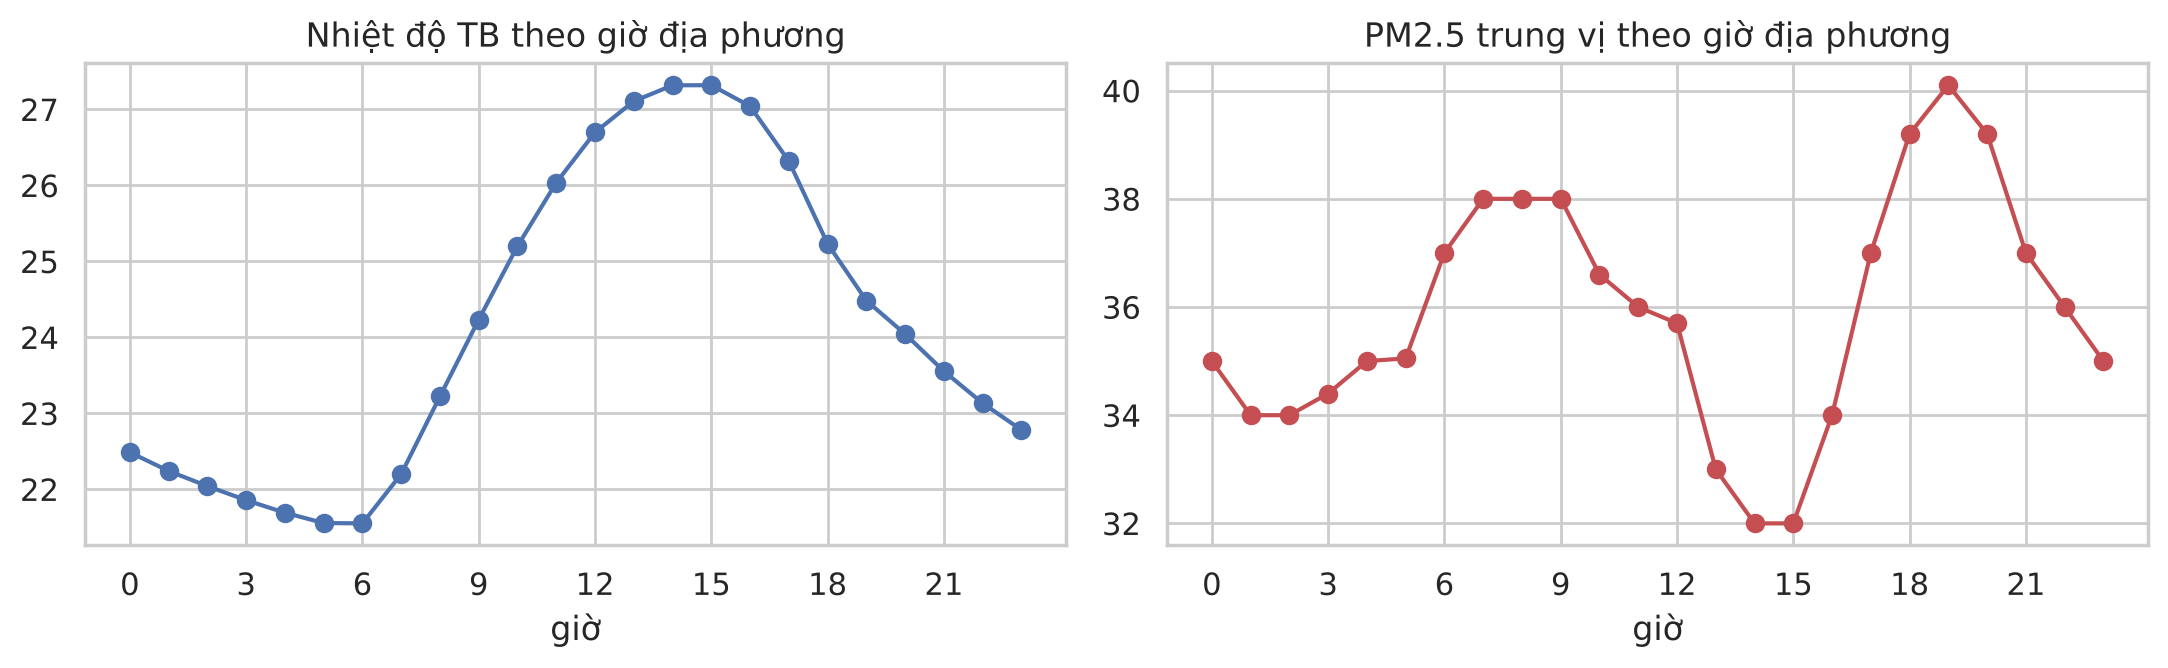

Giờ nhiệt độ cao nhất: 15


In [13]:
df = pm_h.join(wx, how="left")
df["is_valid_pm"] = df["pm25"].notna()

# Kiểm tra chéo múi giờ qua chu kỳ ngày
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.groupby(df.index.hour)["temperature_2m"].mean().plot(ax=ax[0], marker="o", title="Nhiệt độ TB theo giờ địa phương")
df.groupby(df.index.hour)["pm25"].median().plot(ax=ax[1], marker="o", color="C3", title="PM2.5 trung vị theo giờ địa phương")
for a in ax: a.set_xlabel("giờ"); a.set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.savefig(REPORT / "timezone_check.png", dpi=120); plt.show()
if HAS_WX:
    print("Giờ nhiệt độ cao nhất:", df.groupby(df.index.hour)["temperature_2m"].mean().idxmax())

**Kết quả kiểm tra (chạy 22/11/2026):**
- Nhiệt độ trung bình đạt đỉnh lúc **15h** giờ địa phương: không có lệch múi giờ 7 giờ.
- `boundary_layer_height` của Open-Meteo **trống từ 01/01/2024 07:00 đến 01/07/2024 06:00** (khoảng 50% năm 2024), các biến khác đầy đủ. Đây là khoảng trống của nguồn, không phải lỗi ghép. Giai đoạn 2–3 cần xử lý riêng, ví dụ bỏ biến này cho nửa đầu 2024 hoặc thay bằng chênh lệch nhiệt độ ngày–đêm.
- Thử xác minh `TIME_SHIFT_H` bằng độ trễ (lag) cho tương quan âm mạnh nhất giữa dao động trong ngày của log PM2.5 và log độ cao lớp biên, theo từng nửa năm: 2016–2018 cho lag 2–3 giờ, từ nửa cuối 2019 trở đi cho lag 0–1 giờ; nửa đầu 2024 không tính được vì thiếu lớp biên. Cách này **không đủ nhạy** để xác nhận lệch đúng 1 giờ, vì độ trễ còn phụ thuộc thời gian xáo trộn và mùa. Có thể có thay đổi cách gắn nhãn giờ quanh năm 2019, nhưng chưa đủ bằng chứng. **Giữ `TIME_SHIFT_H = -1`** và ghi đây là điểm chưa chắc chắn.

## 5. Tỷ lệ thiếu theo năm và tháng

Hai thước đo:
- **Tỷ lệ giờ thiếu** trong tháng.
- **Tỷ lệ ngày không đủ dữ liệu**: một ngày được coi là "đủ" nếu có ≥ 18/24 giờ hợp lệ (75%). Đây là quy ước phổ biến khi tính trung bình 24 giờ (EPA Mỹ dùng 75%). Giai đoạn 3 cluster theo đường cong 24 giờ nên ngưỡng này quan trọng.
  Lựa chọn khác: ngưỡng chặt hơn (≥ 20 giờ, và không thiếu quá 3 giờ liền), hoặc nội suy rồi dùng hết.

,số giờ,% giờ thiếu,số ngày đủ (≥18h),% ngày không đủ
năm,,,,
2016,8088,9.3,300,11.0
2017,8760,21.1,287,21.4
2018,8760,25.9,240,34.2
2019,8760,41.9,206,43.6
2020,8784,7.6,333,9.0
2021,8760,43.6,203,44.4
2022,8760,64.8,128,64.9
2023,8760,36.3,229,37.3
2024,8784,17.8,302,17.5


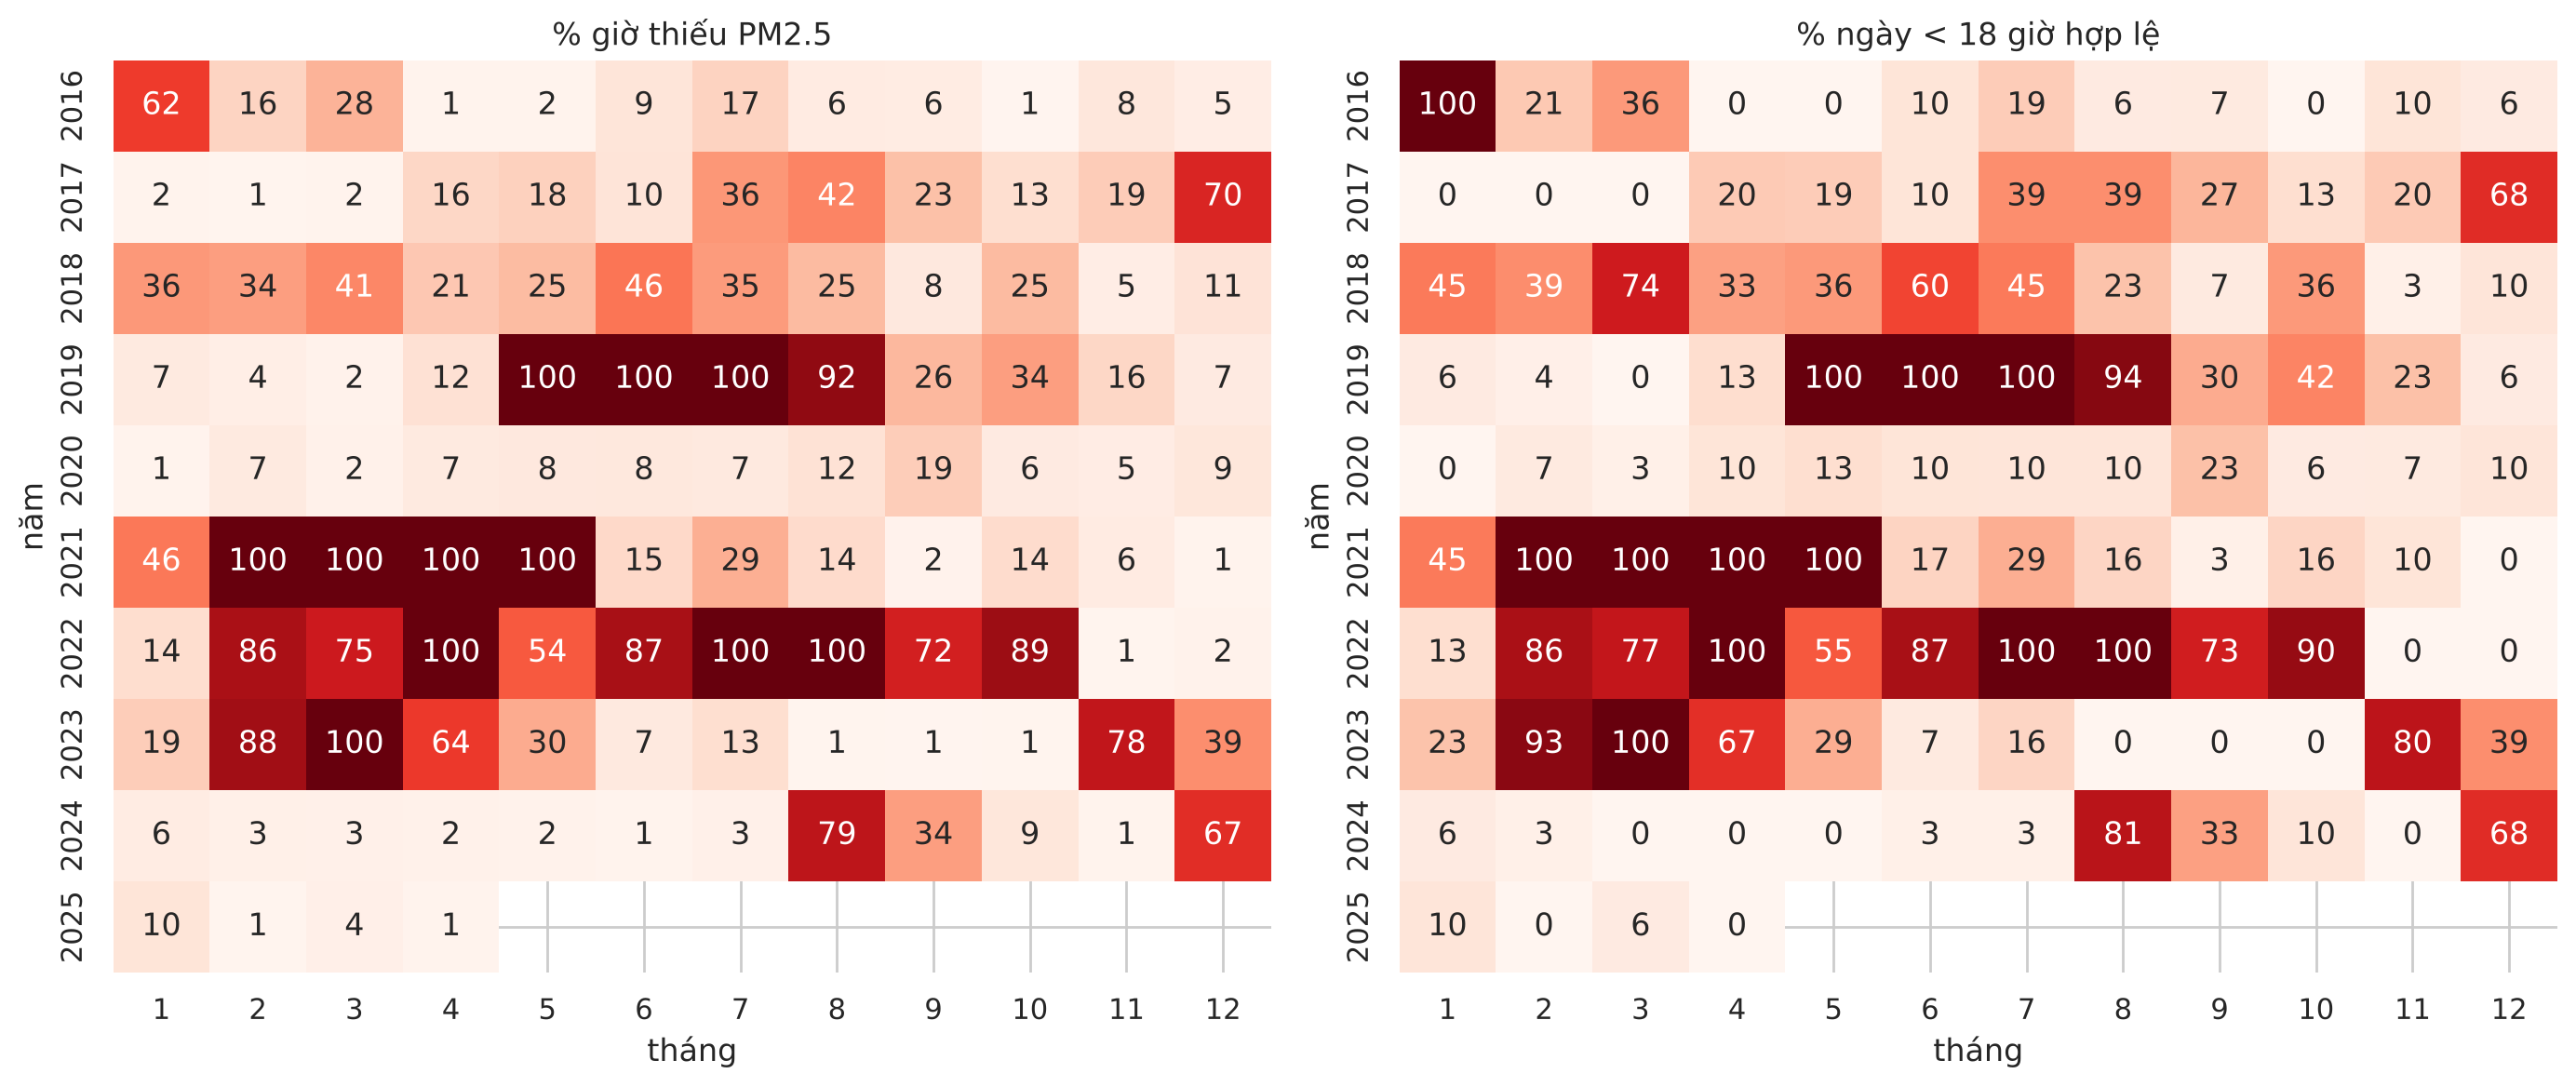

In [14]:
miss_month = (df["pm25"].isna()
              .groupby([df.index.year.rename("năm"), df.index.month.rename("tháng")]).mean()
              .unstack().mul(100).round(1))

daily_n = df["pm25"].notna().groupby(df.index.date).sum()
daily_n.index = pd.to_datetime(daily_n.index)
day_ok = daily_n >= 18
bad_day_month = ((~day_ok).groupby([day_ok.index.year.rename("năm"), day_ok.index.month.rename("tháng")]).mean()
                 .unstack().mul(100).round(1))

miss_year = pd.DataFrame({
    "số giờ": df.groupby(df.index.year).size(),
    "% giờ thiếu": df["pm25"].isna().groupby(df.index.year).mean().mul(100).round(1),
    "số ngày đủ (≥18h)": day_ok.groupby(day_ok.index.year).sum(),
    "% ngày không đủ": (~day_ok).groupby(day_ok.index.year).mean().mul(100).round(1),
})
miss_year.index.name = "năm"
display(miss_year)

fig, ax = plt.subplots(1, 2, figsize=(14, 0.45 * len(miss_month) + 1.5))
sns.heatmap(miss_month, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=ax[0])
ax[0].set_title("% giờ thiếu PM2.5")
sns.heatmap(bad_day_month, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar=False, ax=ax[1])
ax[1].set_title("% ngày < 18 giờ hợp lệ")
plt.tight_layout(); plt.savefig(REPORT / "missing_heatmap.png", dpi=120); plt.show()

miss_year.to_csv(REPORT / "missing_by_year.csv")
miss_month.to_csv(REPORT / "missing_hours_by_month.csv")
bad_day_month.to_csv(REPORT / "incomplete_days_by_month.csv")

In [15]:
# Khoảng trống dài nhất: cần biết để không nội suy qua các đoạn mất dữ liệu lớn
na = df["pm25"].isna()
runs = na.groupby((~na).cumsum()).sum()
gaps = runs[runs > 0].sort_values(ascending=False)
starts = {g: na[(~na).cumsum() == g].index[1] if (~na).cumsum().eq(g).sum() > 1 else None for g in gaps.index[:10]}
print("Phân bố độ dài khoảng thiếu (giờ):\n", pd.cut(gaps, [0, 1, 3, 6, 24, 24*7, 1e9]).value_counts().sort_index())
pd.DataFrame({"bắt đầu": [starts[g] for g in gaps.index[:10]], "dài (giờ)": gaps.values[:10]})

Phân bố độ dài khoảng thiếu (giờ):
 pm25
(0.0, 1.0]               978
(1.0, 3.0]               446
(3.0, 6.0]               106
(6.0, 24.0]              127
(24.0, 168.0]             49
(168.0, 1000000000.0]     15
Name: count, dtype: int64


,bắt đầu,dài (giờ)
0,2021-01-19 00:00:00+07:00,3216
1,2019-04-30 22:00:00+07:00,2880
2,2022-06-07 00:00:00+07:00,2568
3,2023-02-16 07:00:00+07:00,1049
4,2022-03-28 01:00:00+07:00,1028
5,2024-08-07 10:00:00+07:00,820
6,2023-11-07 15:00:00+07:00,730
7,2022-10-01 02:00:00+07:00,665
8,2024-12-11 13:00:00+07:00,556
9,2022-02-03 00:00:00+07:00,504


## 6. Điền khoảng trống ngắn (tách thành cột riêng)

Cột `pm25` giữ nguyên số đo (đã làm sạch, còn NaN). Thêm cột `pm25_filled` chỉ **nội suy tuyến tính các khoảng ≤ 3 giờ**, và cột `flag_interpolated`.
Lý do: clustering đường cong 24 giờ cần vector đủ 24 giá trị; khoảng ngắn nội suy tuyến tính gần đúng vì PM2.5 thay đổi khá trơn theo giờ. Khoảng dài thì không nội suy vì sẽ tạo đường cong giả.
Lựa chọn khác: nội suy theo mùa (dùng profile trung bình giờ của tháng), KNN imputation, hoặc bỏ hẳn ngày có thiếu.

In [16]:
MAX_GAP = 3
s = df["pm25"]
gap_id = s.notna().cumsum()
gap_len = s.isna().groupby(gap_id).transform("sum")
interp = s.interpolate(method="time", limit_area="inside")
df["pm25_filled"] = s.where(s.notna(), interp.where(gap_len <= MAX_GAP))
df["flag_interpolated"] = s.isna() & df["pm25_filled"].notna()
print("Số giờ được nội suy:", int(df["flag_interpolated"].sum()),
      "| còn thiếu sau nội suy:", round(df["pm25_filled"].isna().mean() * 100, 2), "%")

Số giờ được nội suy: 1977 | còn thiếu sau nội suy: 26.79 %


## 7. Lưu bảng sạch

Thêm vài cột thời gian cơ bản (năm, tháng, giờ, thứ) để tiện cho Giai đoạn 2. Các biến lịch (Tết, giãn cách) và điểm cháy sẽ thêm ở bước sau sau khi **tra cứu ngày chính xác**.
Lưu 2 định dạng: Parquet (giữ kiểu dữ liệu và múi giờ, nhỏ, nhanh) và CSV (mở được bằng Excel; thời gian ghi kèm offset `+07:00`).

In [17]:
df["date"] = df.index.tz_localize(None).normalize()
df["year"], df["month"], df["hour"] = df.index.year, df.index.month, df.index.hour
df["dow"] = df.index.dayofweek          # 0 = thứ Hai
df["is_weekend"] = df["dow"] >= 5

flag_cols = [c for c in df.columns if c.startswith("flag_")]
for c in flag_cols:
    df[c] = df[c].fillna(False).astype(bool)

cols = (["pm25", "pm25_filled", "pm25_raw", "is_valid_pm"] + flag_cols +
        [c for c in OM_VARS] + ["wind_u", "wind_v", "wind_sector"] +
        ["date", "year", "month", "hour", "dow", "is_weekend"])
clean = df[cols].copy()
clean.to_parquet(CLEAN / "hanoi_hourly_clean.parquet")
clean.reset_index().assign(time=lambda d: d["time"].map(lambda t: t.isoformat())).to_csv(
    CLEAN / "hanoi_hourly_clean.csv", index=False)
print(clean.shape, "->", CLEAN)
clean.info()

(80592, 28) -> data/clean
<class 'pandas.DataFrame'>
DatetimeIndex: 80592 entries, 2016-01-30 00:00:00+07:00 to 2025-04-09 23:00:00+07:00
Freq: h
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   pm25                   57027 non-null  float64       
 1   pm25_filled            59004 non-null  float64       
 2   pm25_raw               66141 non-null  float64       
 3   is_valid_pm            80592 non-null  bool          
 4   flag_duplicate         80592 non-null  bool          
 5   flag_spike             80592 non-null  bool          
 6   flag_flatline          80592 non-null  bool          
 7   flag_suspect_zero      80592 non-null  bool          
 8   flag_interpolated      80592 non-null  bool          
 9   temperature_2m         80592 non-null  float64       
 10  relative_humidity_2m   80592 non-null  int64         
 11  dew_point_2m           80592 non-null  float64   

## Ghi chú giới hạn
- **Một trạm** (Đại sứ quán Mỹ, quận Ba Đình) không đại diện cho cả Hà Nội.
- Thời tiết là **tái phân tích** cho ô lưới chứa trạm, không phải số đo tại chỗ.
- Thiết bị BAM có sai số khi độ ẩm rất cao; giá trị giờ đơn lẻ nên đọc cùng xu hướng xung quanh.
- Các cờ spike/flatline mới chỉ là gợi ý, chưa loại khỏi dữ liệu.